# Polynomial Linear Regression

In [2]:
# PLR
# It is a simple linear regression
# we will use polynomial feature to improve the accuracy of the model
# Data Behaviour should be curve

In [3]:
import pandas as pd

In [4]:
data = pd.read_csv("Ice_cream selling data.csv")

In [5]:
data.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (°C)         49 non-null     float64
 1   Ice Cream Sales (units)  49 non-null     float64
dtypes: float64(2)
memory usage: 916.0 bytes


In [7]:
data.describe()

,Temperature (°C),Ice Cream Sales (units)
count,49.000000,49.000000
mean,0.271755,15.905308
std,2.697672,12.264682
min,-4.662263,0.328626
25%,-2.111870,4.857988
50%,0.688781,12.615181
75%,2.784836,25.142082
max,4.899032,41.842986


In [8]:
x = data.iloc[:,:-1]

In [9]:
x.head()

,Temperature (°C)
0,-4.662263
1,-4.316559
2,-4.213985
3,-3.949661
4,-3.578554


In [10]:
y = data['Ice Cream Sales (units)']

In [11]:
y.head()

0    41.842986
1    34.661120
2    39.383001
3    37.539845
4    32.284531
Name: Ice Cream Sales (units), dtype: float64

In [12]:
import matplotlib.pyplot as plt

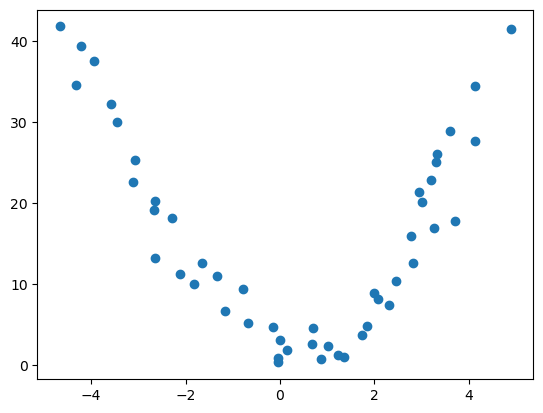

In [13]:
plt.scatter(x,y)
plt.show()

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [15]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state= 42)


In [16]:
x_train.shape

(39, 1)

In [17]:
model = LinearRegression()
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
# Testing Prediction
y_pred = model.predict(x_test)

In [19]:
# Training Prediction
y_pred_train = model.predict(x_train)

In [20]:
r2_score(y_test,y_pred)*100

-57.51270190188227

In [21]:
r2_score(y_train,y_pred_train)*100

6.579063815950037

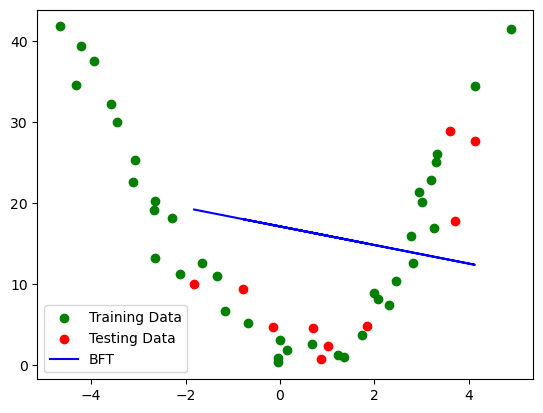

In [22]:
plt.scatter(x_train,y_train, label = "Training Data", color= "Green")
plt.scatter(x_test,y_test, label = "Testing Data", color= "red")
plt.plot(x_test,y_pred, label = "BFT", color = "blue")
plt.legend()
plt.show()

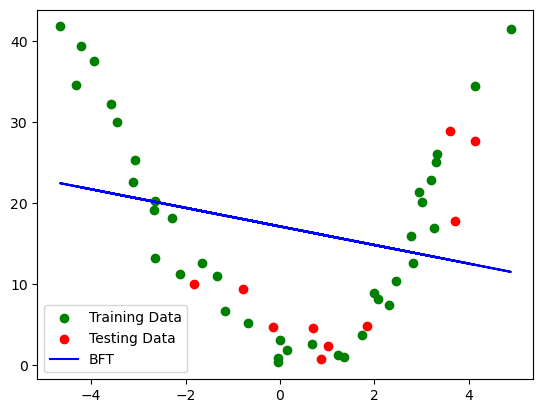

In [23]:
plt.scatter(x_train,y_train, label = "Training Data", color= "Green")
plt.scatter(x_test,y_test, label = "Testing Data", color= "red")
plt.plot(x_train,y_pred_train, label = "BFT", color = "blue")
plt.legend()
plt.show()

In [24]:
# Applying Polynomial Feature to improve Model Accuracy

In [25]:
from sklearn.preprocessing import PolynomialFeatures

In [26]:
poly = PolynomialFeatures(degree=2)

In [27]:
# poly.fit_transform([[5]])
1,x,x**2
x = 3
1,3,9

(1, 3, 9)

In [28]:
new_x_train = poly.fit_transform(x_train)
new_x_test = poly.fit_transform(x_test)

In [29]:
new_x_train
# output comes in array

array([[ 1.00000000e+00, -2.11186969e+00,  4.45999359e+00],
       [ 1.00000000e+00, -3.57855372e+00,  1.28060467e+01],
       [ 1.00000000e+00,  2.31859124e+00,  5.37586534e+00],
       [ 1.00000000e+00, -2.67246083e+00,  7.14204687e+00],
       [ 1.00000000e+00, -3.94966109e+00,  1.55998227e+01],
       [ 1.00000000e+00, -3.10844012e+00,  9.66239999e+00],
       [ 1.00000000e+00,  3.21136614e+00,  1.03128725e+01],
       [ 1.00000000e+00,  3.27004407e+00,  1.06931882e+01],
       [ 1.00000000e+00,  4.13086796e+00,  1.70640701e+01],
       [ 1.00000000e+00, -1.32637898e+00,  1.75928121e+00],
       [ 1.00000000e+00, -2.65228679e+00,  7.03462523e+00],
       [ 1.00000000e+00, -1.17312327e+00,  1.37621820e+00],
       [ 1.00000000e+00,  6.88780908e-01,  4.74419139e-01],
       [ 1.00000000e+00,  2.07510060e+00,  4.30604249e+00],
       [ 1.00000000e+00,  1.74000001e+00,  3.02760004e+00],
       [ 1.00000000e+00, -4.66226268e+00,  2.17366933e+01],
       [ 1.00000000e+00,  3.33593241e+00

In [30]:
new_model = LinearRegression()
new_model.fit(new_x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [31]:
new_y_pred = new_model.predict(new_x_test)

In [32]:
new_y_pred_train = new_model.predict(new_x_train)

In [33]:
r2_score(y_test,new_y_pred)*100

84.30551371938843

In [34]:
r2_score(y_train,new_y_pred_train)*100

94.13665676490518

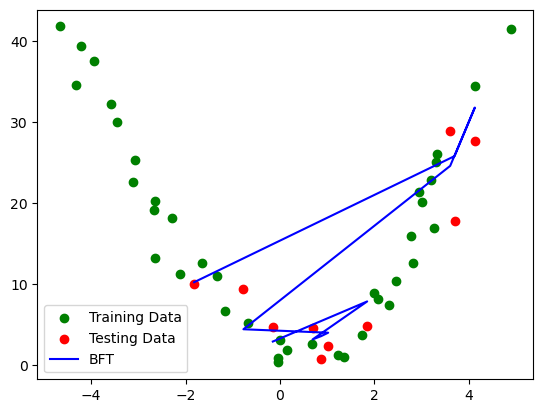

In [36]:
plt.scatter(x_train,y_train, label = "Training Data", color= "Green")
plt.scatter(x_test,y_test, label = "Testing Data", color= "red")
plt.plot(x_test,new_y_pred, label = "BFT", color = "blue")
plt.legend()
plt.show()

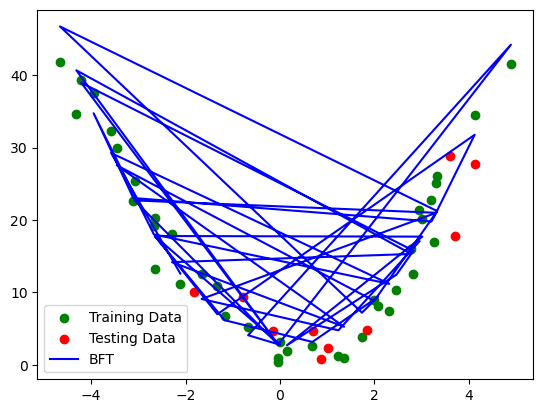

In [37]:
plt.scatter(x_train,y_train, label = "Training Data", color= "Green")
plt.scatter(x_test,y_test, label = "Testing Data", color= "red")
plt.plot(x_train,new_y_pred_train, label = "BFT", color = "blue")
plt.legend()
plt.show()

In [38]:
import joblib
joblib.dump(new_model,"PLR.joblib")

['PLR.joblib']

In [39]:
data.head()

,Temperature (°C),Ice Cream Sales (units)
0,-4.662263,41.842986
1,-4.316559,34.661120
2,-4.213985,39.383001
3,-3.949661,37.539845
4,-3.578554,32.284531


In [40]:
new_model.predict(poly.fit_transform([[-4.662263]]))

array([46.74098561])

In [41]:
joblib.dump(poly,"poly.joblib")

['poly.joblib']